In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/kaggle/input/datasets/airaotieno/climate-change-africa/Africa_climate_change.csv')

df.head()

,DATE,PRCP,TAVG,TMAX,TMIN,COUNTRY
0,19800101 000000,NaN,54.0,61.0,43.0,Tunisia
1,19800101 000000,NaN,49.0,55.0,41.0,Tunisia
2,19800101 000000,0.0,72.0,86.0,59.0,Cameroon
3,19800101 000000,NaN,50.0,55.0,43.0,Tunisia
4,19800101 000000,NaN,75.0,91.0,NaN,Cameroon


In [4]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (464815, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 464815 entries, 0 to 464814
Data columns (total 6 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   DATE     464815 non-null  object 
 1   PRCP     177575 non-null  float64
 2   TAVG     458439 non-null  float64
 3   TMAX     363901 non-null  float64
 4   TMIN     332757 non-null  float64
 5   COUNTRY  464815 non-null  object 
dtypes: float64(4), object(2)
memory usage: 21.3+ MB


In [5]:
df.isnull().sum()

DATE            0
PRCP       287240
TAVG         6376
TMAX       100914
TMIN       132058
COUNTRY         0
dtype: int64

In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 2705


In [9]:
df[df.duplicated(keep=False)].head(10)

,DATE,PRCP,TAVG,TMAX,TMIN,COUNTRY
72,19800104 000000,0.0,77.0,91.0,64.0,Senegal
83,19800104 000000,0.0,77.0,91.0,64.0,Senegal
126,19800106 000000,NaN,53.0,63.0,43.0,Tunisia
137,19800106 000000,NaN,53.0,63.0,43.0,Tunisia
356,19800115 000000,NaN,82.0,NaN,NaN,Cameroon
360,19800115 000000,NaN,82.0,NaN,NaN,Cameroon
700,19800129 000000,NaN,55.0,59.0,52.0,Tunisia
703,19800129 000000,NaN,55.0,59.0,52.0,Tunisia
939,19800209 000000,0.0,79.0,NaN,64.0,Senegal
940,19800209 000000,0.0,79.0,NaN,64.0,Senegal


In [10]:
df = df.drop_duplicates()

print("Duplicates remaining:", df.duplicated().sum())

Duplicates remaining: 0


In [7]:
df[['PRCP', 'TAVG', 'TMAX', 'TMIN']].describe()

,PRCP,TAVG,TMAX,TMIN
count,177575.000000,458439.000000,363901.000000,332757.000000
mean,0.120941,77.029838,88.713969,65.548262
std,0.486208,11.523634,13.042631,11.536547
min,0.000000,-49.000000,41.000000,12.000000
25%,0.000000,70.000000,81.000000,58.000000
50%,0.000000,80.000000,90.000000,68.000000
75%,0.010000,85.000000,99.000000,74.000000
max,19.690000,110.000000,123.000000,97.000000


In [8]:
print(df['DATE'].head(10))
print("\nDate data type:", df['DATE'].dtype)

0    19800101 000000
1    19800101 000000
2    19800101 000000
3    19800101 000000
4    19800101 000000
5    19800101 000000
6    19800101 000000
7    19800101 000000
8    19800101 000000
9    19800101 000000
Name: DATE, dtype: object

Date data type: object


In [11]:
print("Date data type:", df['DATE'].dtype)

print("\nFirst 10 dates:")
print(df['DATE'].head(10))

Date data type: object

First 10 dates:
0    19800101 000000
1    19800101 000000
2    19800101 000000
3    19800101 000000
4    19800101 000000
5    19800101 000000
6    19800101 000000
7    19800101 000000
8    19800101 000000
9    19800101 000000
Name: DATE, dtype: object


In [12]:
df['DATE'] = pd.to_datetime(
    df['DATE'],
    format='%Y%m%d %H%M%S'
)

print(df['DATE'].dtype)
print(df['DATE'].head())

datetime64[ns]
0   1980-01-01
1   1980-01-01
2   1980-01-01
3   1980-01-01
4   1980-01-01
Name: DATE, dtype: datetime64[ns]


In [13]:
print("Earliest date:", df['DATE'].min())
print("Latest date:", df['DATE'].max())

Earliest date: 1980-01-01 00:00:00
Latest date: 2023-08-23 00:00:00


In [14]:
df['COUNTRY'].value_counts()

COUNTRY
Senegal     181513
Egypt       148676
Tunisia      79064
Cameroon     41398
Angola       11459
Name: count, dtype: int64

In [15]:
print("Missing average temperatures:", df['TAVG'].isnull().sum())

print("Available average temperatures:", df['TAVG'].count())

Missing average temperatures: 6375
Available average temperatures: 455735


In [16]:
df['YEAR'] = df['DATE'].dt.year

selected_countries = df[
    df['COUNTRY'].isin(['Tunisia', 'Cameroon'])
]

yearly_temps = selected_countries.groupby(
    ['YEAR', 'COUNTRY']
)['TAVG'].mean().reset_index()

yearly_temps.head(10)

,YEAR,COUNTRY,TAVG
0,1980,Cameroon,78.256522
1,1980,Tunisia,64.865237
2,1981,Cameroon,78.145993
3,1981,Tunisia,66.078962
4,1982,Cameroon,77.373083
5,1982,Tunisia,66.806824
6,1983,Cameroon,78.407674
7,1983,Tunisia,66.408163
8,1984,Cameroon,78.657471
9,1984,Tunisia,65.297849


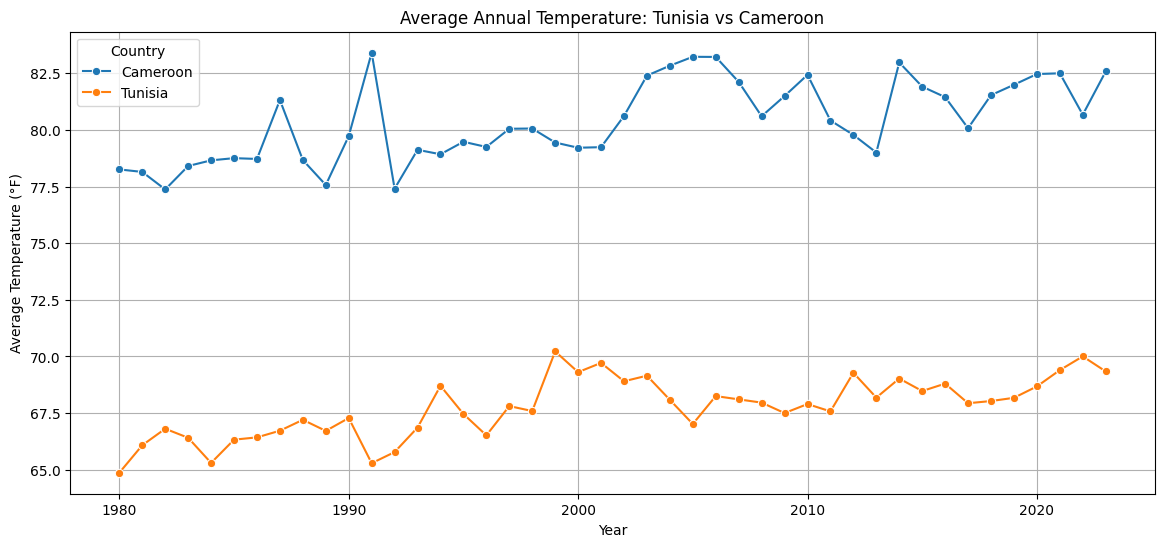

In [17]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_temps,
    x='YEAR',
    y='TAVG',
    hue='COUNTRY',
    marker='o'
)

plt.title('Average Annual Temperature: Tunisia vs Cameroon')
plt.xlabel('Year')
plt.ylabel('Average Temperature (°F)')
plt.legend(title='Country')
plt.grid(True)

plt.show()

### Temperature Trends in Tunisia and Cameroon (1980–2023)

The line chart illustrates the annual average temperature fluctuations in Tunisia and Cameroon between 1980 and 2023.

Cameroon consistently recorded higher average temperatures than Tunisia throughout the observation period. Cameroon's temperatures generally ranged between approximately 77°F and 83°F, while Tunisia's ranged between approximately 65°F and 70°F.

Both countries demonstrate an overall upward temperature trend, although fluctuations occurred in individual years. Cameroon experienced some noticeable variations during the early 1990s and mid-2000s, while Tunisia showed fluctuations around 1991 and 1999.

Overall, the visualization suggests a gradual increase in average temperatures in both countries over the period studied.

In [18]:
zoomed_data = yearly_temps[
    (yearly_temps['YEAR'] >= 1980) &
    (yearly_temps['YEAR'] <= 2005)
]

print("Starting year:", zoomed_data['YEAR'].min())
print("Ending year:", zoomed_data['YEAR'].max())

Starting year: 1980
Ending year: 2005


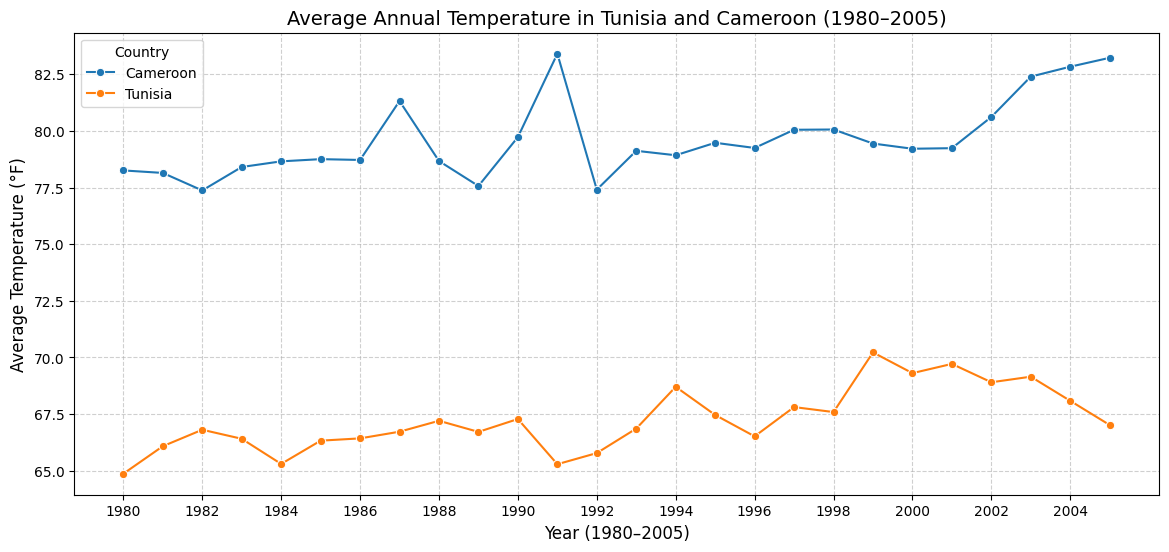

In [19]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=zoomed_data,
    x='YEAR',
    y='TAVG',
    hue='COUNTRY',
    marker='o'
)

plt.title('Average Annual Temperature in Tunisia and Cameroon (1980–2005)',
          fontsize=14)

plt.xlabel('Year (1980–2005)', fontsize=12)
plt.ylabel('Average Temperature (°F)', fontsize=12)

plt.xticks(range(1980, 2006, 2))
plt.legend(title='Country')
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

### Temperature Trends Between 1980 and 2005

The zoomed-in line chart provides a closer examination of annual average temperatures in Tunisia and Cameroon between 1980 and 2005.

Cameroon consistently recorded higher average temperatures than Tunisia throughout the period. Cameroon's temperatures experienced noticeable fluctuations, particularly in 1991 and 1992. Tunisia also experienced variations, with a notable increase around 1999.

Overall, both countries displayed fluctuations in annual average temperatures, while Cameroon maintained a consistently higher temperature level than Tunisia.

In [20]:
# Select records belonging to Senegal
senegal = df[df['COUNTRY'] == 'Senegal'].copy()

# Extract the year
senegal['YEAR'] = senegal['DATE'].dt.year

# Select the two periods
period_1 = senegal[
    (senegal['YEAR'] >= 1980) &
    (senegal['YEAR'] <= 2000)
]

period_2 = senegal[
    (senegal['YEAR'] >= 2000) &
    (senegal['YEAR'] <= 2023)
]

# Remove missing average temperature readings
period_1 = period_1['TAVG'].dropna()
period_2 = period_2['TAVG'].dropna()

# Check the number of observations
print("1980–2000 observations:", len(period_1))
print("2000–2023 observations:", len(period_2))

1980–2000 observations: 87621
2000–2023 observations: 96089


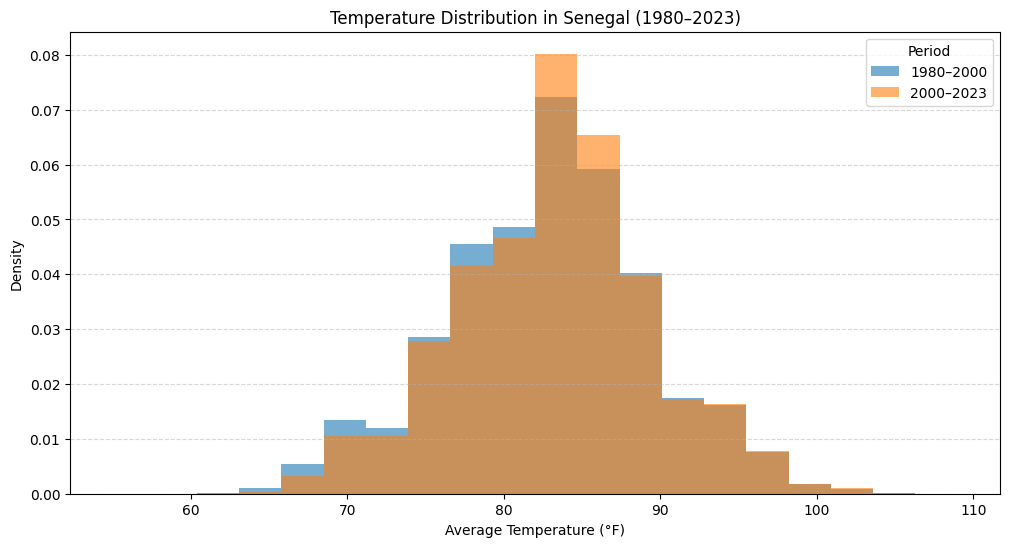

In [21]:
# Create a figure
plt.figure(figsize=(12, 6))

# Create common histogram bins
all_temps = pd.concat([period_1, period_2])
bins = np.histogram_bin_edges(all_temps, bins=20)

# First period
plt.hist(
    period_1,
    bins=bins,
    alpha=0.6,
    label='1980–2000',
    density=True
)

# Second period
plt.hist(
    period_2,
    bins=bins,
    alpha=0.6,
    label='2000–2023',
    density=True
)

# Customize the chart
plt.title('Temperature Distribution in Senegal (1980–2023)')
plt.xlabel('Average Temperature (°F)')
plt.ylabel('Density')
plt.legend(title='Period')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

### Temperature Distribution in Senegal (1980–2023)

The overlapping histograms compare the distribution of average temperatures in Senegal across two periods: 1980–2000 and 2000–2023.

Both distributions show a high concentration of temperature observations between approximately 80°F and 90°F, with the highest density occurring around 83°F–87°F.

The two distributions overlap considerably, indicating similarities in Senegal's temperature patterns across the two periods. However, the more recent period appears to have a slightly greater concentration of observations within some of the higher temperature ranges.

Overall, the visualization suggests some changes in the distribution of temperatures over time, although the substantial overlap indicates that the general temperature distribution remained relatively similar.

In [22]:
country_avg = df.groupby('COUNTRY')['TAVG'].mean()

print(country_avg)

COUNTRY
Angola      75.931818
Cameroon    80.301826
Egypt       73.847244
Senegal     82.964091
Tunisia     67.740539
Name: TAVG, dtype: float64


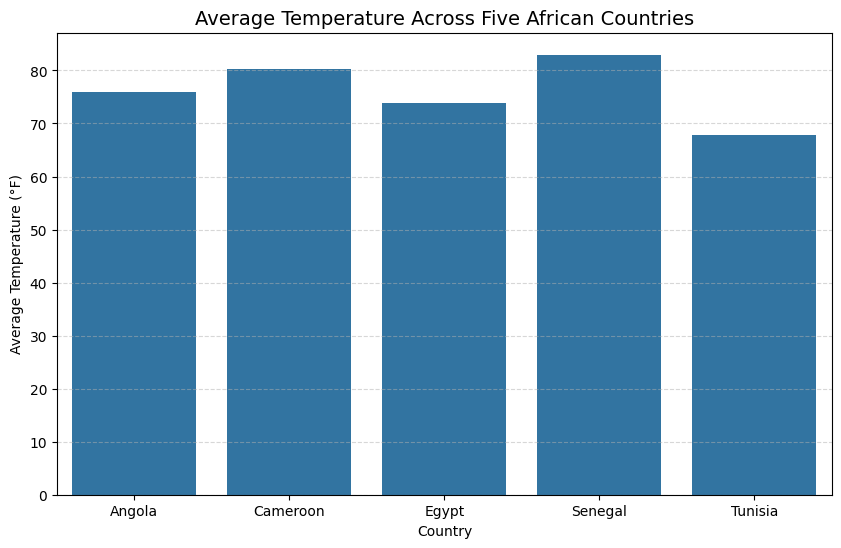

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_avg.index,
    y=country_avg.values
)

plt.title('Average Temperature Across Five African Countries',
          fontsize=14)

plt.xlabel('Country')
plt.ylabel('Average Temperature (°F)')

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

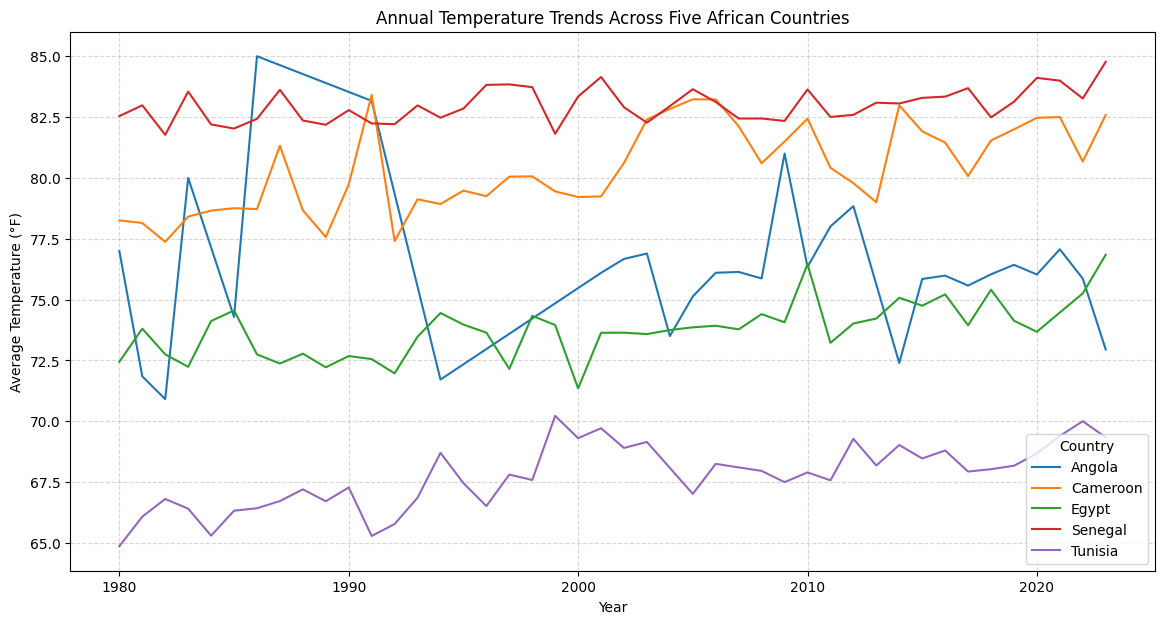

In [24]:
# Calculate annual average temperature for all countries
all_yearly_temps = df.groupby(
    ['YEAR', 'COUNTRY']
)['TAVG'].mean().reset_index()

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=all_yearly_temps,
    x='YEAR',
    y='TAVG',
    hue='COUNTRY'
)

plt.title('Annual Temperature Trends Across Five African Countries')
plt.xlabel('Year')
plt.ylabel('Average Temperature (°F)')
plt.legend(title='Country')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

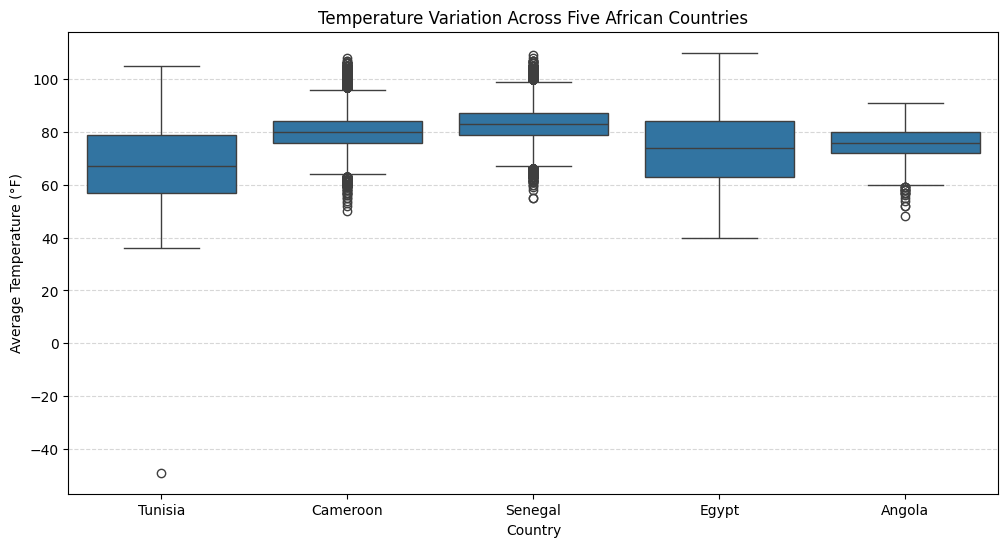

In [25]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='COUNTRY',
    y='TAVG'
)

plt.title('Temperature Variation Across Five African Countries')
plt.xlabel('Country')
plt.ylabel('Average Temperature (°F)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

### Average Temperature Comparison Across Five African Countries

The bar chart compares the overall average temperatures recorded in Angola, Cameroon, Egypt, Senegal and Tunisia.

Senegal recorded the highest average temperature at approximately 83°F, followed by Cameroon at approximately 80°F. Angola and Egypt recorded intermediate averages of approximately 76°F and 74°F, respectively. Tunisia recorded the lowest average temperature at approximately 68°F.

The visualization demonstrates noticeable differences in average temperatures among the five countries. A bar chart is particularly effective for this comparison because it allows the reader to easily identify and compare the average temperature of each country.

In [26]:
# Compare annual average temperatures in 1980 and 2022
comparison = all_yearly_temps[
    all_yearly_temps['YEAR'].isin([1980, 2022])
]

comparison_pivot = comparison.pivot(
    index='COUNTRY',
    columns='YEAR',
    values='TAVG'
)

comparison_pivot['Temperature Change'] = (
    comparison_pivot[2022] - comparison_pivot[1980]
)

comparison_pivot = comparison_pivot.sort_values(
    'Temperature Change',
    ascending=False
)

print(comparison_pivot)

YEAR           1980       2022  Temperature Change
COUNTRY                                           
Tunisia   64.865237  70.002205            5.136969
Egypt     72.443825  75.252514            2.808688
Cameroon  78.256522  80.672781            2.416259
Senegal   82.539307  83.263094            0.723787
Angola    77.000000  75.861204           -1.138796


In [27]:
df[df['TAVG'] < 40][
    ['DATE', 'COUNTRY', 'TAVG', 'TMAX', 'TMIN']
].head(20)

,DATE,COUNTRY,TAVG,TMAX,TMIN
8399,1980-12-01,Tunisia,38.0,46.0,34.0
8621,1980-12-11,Tunisia,38.0,59.0,28.0
8625,1980-12-11,Tunisia,38.0,52.0,28.0
8667,1980-12-13,Tunisia,39.0,57.0,18.0
8728,1980-12-15,Tunisia,39.0,59.0,25.0
8738,1980-12-16,Tunisia,39.0,57.0,27.0
9255,1981-01-08,Tunisia,39.0,43.0,NaN
9256,1981-01-08,Tunisia,37.0,41.0,NaN
9265,1981-01-08,Tunisia,36.0,NaN,NaN
9272,1981-01-09,Tunisia,38.0,45.0,34.0


In [28]:
# Calculate temperature variation by country
temperature_variation = df.groupby('COUNTRY')['TAVG'].agg(
    ['mean', 'std', 'min', 'max']
)

# Calculate interquartile range
iqr = df.groupby('COUNTRY')['TAVG'].quantile(0.75) - \
      df.groupby('COUNTRY')['TAVG'].quantile(0.25)

temperature_variation['IQR'] = iqr

print(temperature_variation.sort_values('IQR', ascending=False))


               mean        std   min    max   IQR
COUNTRY                                          
Tunisia   67.740539  12.772608 -49.0  105.0  22.0
Egypt     73.847244  12.511408  40.0  110.0  21.0
Angola    75.931818   5.059865  48.0   91.0   8.0
Cameroon  80.301826   7.100121  50.0  108.0   8.0
Senegal   82.964091   6.414957  55.0  109.0   8.0


In [29]:
df[df['TAVG'] == -49][
    ['DATE', 'COUNTRY', 'TAVG', 'TMAX', 'TMIN']
]

,DATE,COUNTRY,TAVG,TMAX,TMIN
460304,2023-04-01,Tunisia,-49.0,NaN,NaN


In [30]:
df = df[df['TAVG'] != -49].copy()

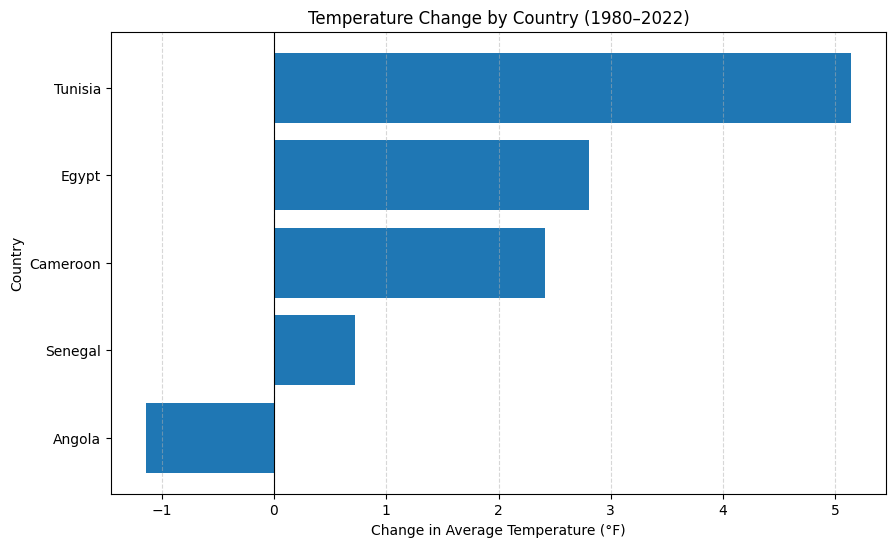

In [31]:
plt.figure(figsize=(10, 6))

changes = comparison_pivot['Temperature Change'].sort_values()

plt.barh(changes.index, changes.values)

plt.axvline(x=0, color='black', linewidth=0.8)

plt.title('Temperature Change by Country (1980–2022)')
plt.xlabel('Change in Average Temperature (°F)')
plt.ylabel('Country')

plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.show()

In [32]:
import numpy as np

# Replace the suspicious temperature reading
df.loc[df['TAVG'] == -49, 'TAVG'] = np.nan

# Confirm the correction
print(df[df['COUNTRY'] == 'Tunisia']['TAVG'].min())

36.0


In [33]:
temperature_variation = df.groupby('COUNTRY')['TAVG'].agg(
    ['mean', 'std', 'min', 'max']
)

iqr = (
    df.groupby('COUNTRY')['TAVG'].quantile(0.75)
    - df.groupby('COUNTRY')['TAVG'].quantile(0.25)
)

temperature_variation['IQR'] = iqr

print(temperature_variation)

               mean        std   min    max   IQR
COUNTRY                                          
Angola    75.931818   5.059865  48.0   91.0   8.0
Cameroon  80.301826   7.100121  50.0  108.0   8.0
Egypt     73.847244  12.511408  40.0  110.0  21.0
Senegal   82.964091   6.414957  55.0  109.0   8.0
Tunisia   67.742016  12.765939  36.0  105.0  22.0


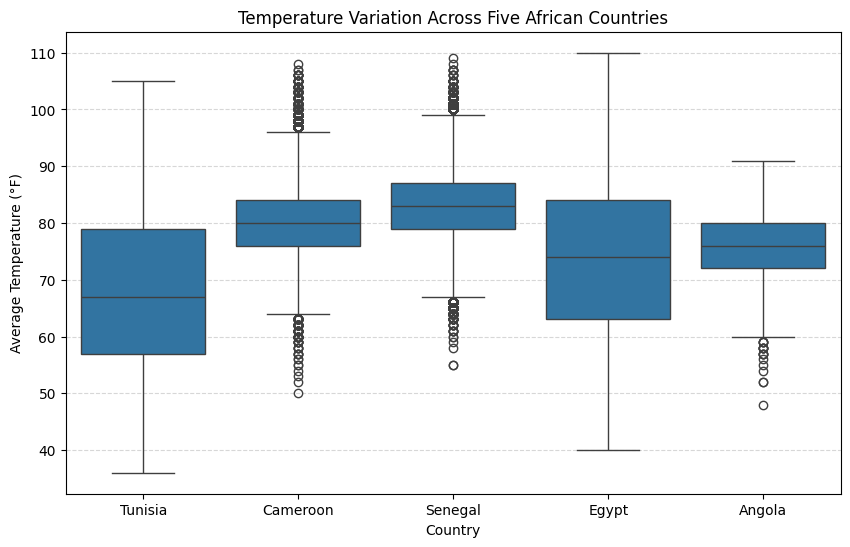

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='COUNTRY', y='TAVG')

plt.title('Temperature Variation Across Five African Countries')
plt.xlabel('Country')
plt.ylabel('Average Temperature (°F)')

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

### Identification and Treatment of Outliers

During data exploration, an unusual temperature observation of -49°F was identified for Tunisia on 1 April 2023. The record also contained missing maximum and minimum temperature values, suggesting a possible data-entry or measurement error.

To prevent this observation from distorting the statistical analysis, its average temperature value was replaced with a missing value (NaN), while retaining the remaining information in the record.

This correction helped improve the reliability of subsequent statistical calculations and visualizations.

## Conclusion

The analysis of historical temperature data from five African countries between 1980 and 2023 revealed differences in temperature patterns, distributions and fluctuations.

The comparison between Tunisia and Cameroon showed that Cameroon consistently recorded higher average temperatures throughout the period. Both countries experienced fluctuations, although their annual temperature patterns differed.

The comparison of Senegal's temperature distributions across 1980–2000 and 2000–2023 showed considerable overlap, suggesting similarities in the distribution of recorded temperatures across the two periods.

The comparison of average temperatures across the five countries identified Senegal as having the highest average temperature, followed by Cameroon, Angola, Egypt and Tunisia.

Further analysis comparing 1980 and 2022 revealed that Tunisia experienced the largest increase in average temperature, approximately 5.14°F, while Angola recorded a decrease of approximately 1.14°F.

The boxplot analysis also revealed that Tunisia and Egypt had the greatest variability in their daily average temperatures. During data cleaning, an unusually low temperature observation of -49°F was identified and treated as missing to improve the reliability of the analysis.

Overall, the findings demonstrate that temperature patterns and variability differ across the five countries. The visualizations provided useful insights into historical temperature fluctuations and highlighted the importance of data cleaning and appropriate visualization techniques when analysing climate data.